<a href="https://colab.research.google.com/github/rifahnanjiba02-arch/vision-language-composition/blob/main/scripts/MACCO_W1_CML_Traffic_Reviewed_MultiObject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MACCO W1+CML → Reviewed Traffic Masking & Noise (small Colab pilot)

**Goal:** Continue from **our W1+CML CLIP checkpoint**. In this version, we also preserve **per-object visual patch masks**, ensuring the noise stage corrupts at least two different objects in every selected example. Rebuild the authors' image/text predictor heads and train with the **four official MACCO losses, reviewed target-crop CML, and small noise consistency**.

**Start small:** 512 candidate training records + 96 validation records, then retain only usable multi-object scenes. YOLO looks for additional *estimated* object regions in two-image batches; Talk2Car-Expr provides just **one official target box** per record.

**Mandatory review gate:** We generate an easy-to-audit packet containing target crop, full image, correct color/object prompt and a *proposed* incorrect-color prompt. **You must inspect every proposed pair** and then list rejected row IDs in the A12 approval cell. The cell starts locked (`REVIEWED_ALL = False`) until you explicitly confirm review is complete. No unreviewed or rejected caption ever enters CML. Unreviewed traffic examples still contribute to the four original MACCO objectives.

**Method:** Mask multiple image patches that overlap the annotated target and detected neighbors; independently mask selected text tokens. On alternate batches, place pixel noise on other object patches and embedding noise at selected text positions. The mask/noise mechanism is an adaptation of MACCO, **not an exact reproduction** of the authors' original scene-graph masks.

**Outputs:** full resumable MACCO weights (including your newly trained predictor heads), separate CLIP-only weights for Table 1/21, and actual review/training/validation reports.

**Sources:** [MACCO implementation](https://github.com/hiker-lw/MACCO) · [MACCO loss](https://github.com/hiker-lw/MACCO/blob/main/src/open_clip_code/loss_fn/MACCO_CLIP_loss_text_image_raw_space.py) · [Talk2Car-Expr](https://github.com/ThierryDeruyttere/Talk2Car-Expr) · [Official image source](https://github.com/talk2car/Talk2Car#talk2carslim)

**Run in a Colab GPU runtime, in order.** The notebook is statically checked, but full GPU training has not been executed here. Inspect the previews and smoke test before starting training.

## A1 · Install packages

Only install what the official MACCO source and our data adapter need. Restart Colab if pip explicitly asks for it.

In [2]:
%pip -q install "timm==1.0.15" ftfy regex "webdataset==0.2.111" braceexpand easydict PyYAML open_clip_torch==2.32.0 huggingface_hub gdown ultralytics pandas matplotlib pillow tqdm requests

## A2 · Choose one small, reproducible experiment

**512 training candidates / 96 validation candidates** are sampled from the official splits. Some examples may be excluded after checking distinct object patches. We audit up to **96 training and 24 validation color negatives**; you must approve/reject each one before training. No whole-scene negative is inferred from the color labels.

In [24]:
from pathlib import Path
import os, sys, subprocess, json, random, gc, zipfile, shutil, math, hashlib
from collections import Counter
import numpy as np, pandas as pd, requests, gdown, torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

assert torch.cuda.is_available(), 'Select Runtime → Change runtime type → GPU.'
DEVICE = torch.device('cuda')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

WORK = Path('/content/macco_traffic_w1_cml')
IMAGES = WORK / 'images'
OUT = WORK / 'outputs'
for folder in (WORK, IMAGES, OUT): folder.mkdir(parents=True, exist_ok=True)

HF_REPO = 'rifahnanjiba2/MACCO-Finetuned'
HF_FILE = 'MACCO-W1-CML-ViT-B-32.pt'  # YOUR encoder; do not overwrite this

TRAIN_CANDIDATES = 512
VAL_CANDIDATES = 96
REVIEW_TRAIN = 96              # Maximum proposed negative pairs to review
REVIEW_VAL = 24
BATCH_SIZE = 2                 # Small enough for full MACCO reconstruction heads
GRAD_ACCUM = 4
HEAD_WARMUP_BATCHES = 40       # Fresh reconstruction heads; CLIP remains frozen
ADAPT_EPOCHS = 3
MAX_ADAPT_BATCHES = None       # Optional: 20 for a quick GPU test
LR_VISUAL = 5e-7
LR_HEADS = 1e-4
PIXEL_NOISE_SIGMA = 0.06       # Noise standard deviation in [0,1] RGB space
MASK_MODE_PROB = 0.5
MAX_OBJECT_REGIONS = 3

# Preserve the prior W1 weights for the original four MACCO losses.
W_CONTRAST, W_INTRA, W_TEXT_RECON, W_IMAGE_RECON = 1.0, 0.2, 25.0, 250.0
W_CML, CML_MARGIN, W_NOISE = 1.0, 0.05, 0.1

print('GPU:', torch.cuda.get_device_name(0))
print('Candidate rows:', TRAIN_CANDIDATES, 'train +', VAL_CANDIDATES, 'validation')
print('Review capacity:', REVIEW_TRAIN, 'training pairs +', REVIEW_VAL, 'validation pairs')
print('Batch size:', BATCH_SIZE, '| gradient accumulation:', GRAD_ACCUM)

GPU: Tesla T4
Candidate rows: 512 train + 96 validation
Review capacity: 96 training pairs + 24 validation pairs
Batch size: 2 | gradient accumulation: 4


## A3 · Download annotation JSON, **before images**

A record is a street image plus an official target box, color, class, action, location, and a short **referring expression**. We print examples rather than assume what the data contains.

In [4]:
BASE = 'https://raw.githubusercontent.com/ThierryDeruyttere/Talk2Car-Expr/main/data/'

def read_annotations(split):
    local = WORK / f'talk2car_expr_{split}.json'
    if not local.exists():
        response = requests.get(BASE + local.name, timeout=120)
        response.raise_for_status(); local.write_bytes(response.content)
    raw = json.loads(local.read_text())
    rows = []
    for uid, a in raw.items():
        fields = ('img','obj_box','class','color','description')
        if not all(key in a for key in fields): continue
        if not str(a['description']).strip(): continue
        box = a['obj_box']
        if len(box)!=4 or min(float(v) for v in box[2:])<=0: continue
        rows.append(dict(id=uid, split=split, img=str(a['img']),
                         box=[float(v) for v in box], cls=str(a['class']),
                         color=str(a['color']), action=str(a.get('action','')),
                         location=str(a.get('location','')),
                         description=str(a['description']).strip()))
    return rows

all_train = read_annotations('train')
all_val = read_annotations('val')
print('Annotation rows:',len(all_train),'train,',len(all_val),'validation')
print(pd.DataFrame(all_train[:6])[['img','cls','color','location','description','box']].to_string(index=False))
print('\nTop classes:', Counter(r['cls'] for r in all_train).most_common(10))
print('Top colors:', Counter(r['color'] for r in all_train).most_common(10))
assert all_train and all_val


Annotation rows: 8349 train, 1163 validation
        img                       cls color location             description                          box
train_0.jpg    human.pedestrian.adult black     left     first adult on left   [529.0, 458.0, 24.0, 41.0]
train_1.jpg               vehicle.car white     left      first car in front  [790.0, 463.0, 174.0, 80.0]
train_2.jpg               vehicle.car white     left      first car in front [822.0, 467.0, 137.0, 113.0]
train_3.jpg               vehicle.car white in front      first car in front  [809.0, 465.0, 103.0, 84.0]
train_4.jpg human.pedestrian.stroller black    right first stroller on right  [1443.0, 512.0, 47.0, 40.0]
train_5.jpg               vehicle.car white in front      first car in front [778.0, 459.0, 158.0, 129.0]

Top classes: [('vehicle.car', 3817), ('human.pedestrian.adult', 1873), ('vehicle.truck', 961), ('vehicle.bus.rigid', 300), ('movable_object.trafficcone', 237), ('vehicle.bicycle', 190), ('vehicle.motorcycle', 187

## A4 · Select a manageable candidate subset **before downloading/extracting**

Sampling is seeded and uses **different official splits**. We keep a variety of classes. Save exact selected IDs for repeatability.

In [5]:
train_candidates = random.Random(SEED).sample(all_train, min(TRAIN_CANDIDATES,len(all_train)))
val_candidates = random.Random(SEED+1).sample(all_val, min(VAL_CANDIDATES,len(all_val)))
selected = train_candidates + val_candidates
assert not ({r['img'] for r in train_candidates} & {r['img'] for r in val_candidates}), 'Train/validation images overlap.'
required = {r['img'] for r in selected}
print('Candidate rows:',len(train_candidates),'train,',len(val_candidates),'val')
print('Unique required filenames:',len(required))
pd.DataFrame(selected).to_csv(OUT/'selected_before_crowd_filter.csv',index=False)

Candidate rows: 512 train, 96 val
Unique required filenames: 608


## A5 · Download the authors' image archive; **correct the filename mismatch**

This public ZIP (~1.77 GB) comes from Talk2Car's official link, **not your personal Google Drive**. The original archive uses names like `img_train_0.jpg`; Talk2Car-Expr uses `train_0.jpg`. We rename extracted copies only. **If the names differ again, print actual ZIP members and fail with a clear error.** After a Colab reset, temporary files must be downloaded again unless you provide an existing ZIP path.

In [6]:
OFFICIAL_ID='1bhcdej7IFj5GqfvXGrHGPk2Knxe77pek'
ZIP_PATH = WORK/'imgs.zip'
EXISTING_ZIP_PATH = ''  # Optional: put existing imgs.zip in /content and set this path.
if EXISTING_ZIP_PATH:
    ZIP_PATH = Path(EXISTING_ZIP_PATH)

missing = {name for name in required if not (IMAGES/name).is_file()}
print('Missing selected images:',len(missing))
if missing:
    if not ZIP_PATH.is_file():
        result = gdown.download(id=OFFICIAL_ID, output=str(ZIP_PATH), quiet=False)
        assert result and ZIP_PATH.is_file(), 'Official image ZIP download failed.'
    assert zipfile.is_zipfile(ZIP_PATH), f'Not a ZIP: {ZIP_PATH}'

    with zipfile.ZipFile(ZIP_PATH) as z:
        infos = [m for m in z.infolist() if not m.is_dir()]
        print('Archive name examples:', [m.filename for m in infos[:7]])
        # Match either the corrected or already-correct name.
        wanted=[]
        for info in infos:
            source_name=Path(info.filename).name
            corrected=source_name[4:] if source_name.startswith(('img_train_','img_val_')) else source_name
            if corrected in missing: wanted.append((info,corrected))
        print('Matching selected filenames:',len(wanted),'/',len(missing))
        assert wanted, 'No matching names; inspect Archive name examples above.'
        for info,name in tqdm(wanted, desc='Extracting selected images'):
            with z.open(info) as src, (IMAGES/name).open('wb') as dst:
                shutil.copyfileobj(src,dst)

remaining=[name for name in required if not (IMAGES/name).is_file()]
assert not remaining, f'Missing images after extraction: {remaining[:10]}'
print('Ready:',len(required),'unique selected image files')

Missing selected images: 0
Ready: 608 unique selected image files


## A6 · Inspect six images with official targets

The **red rectangle is ground truth** supplied by Talk2Car-Expr. The rest of the traffic objects are still unannotated here. This cell does not run YOLO.

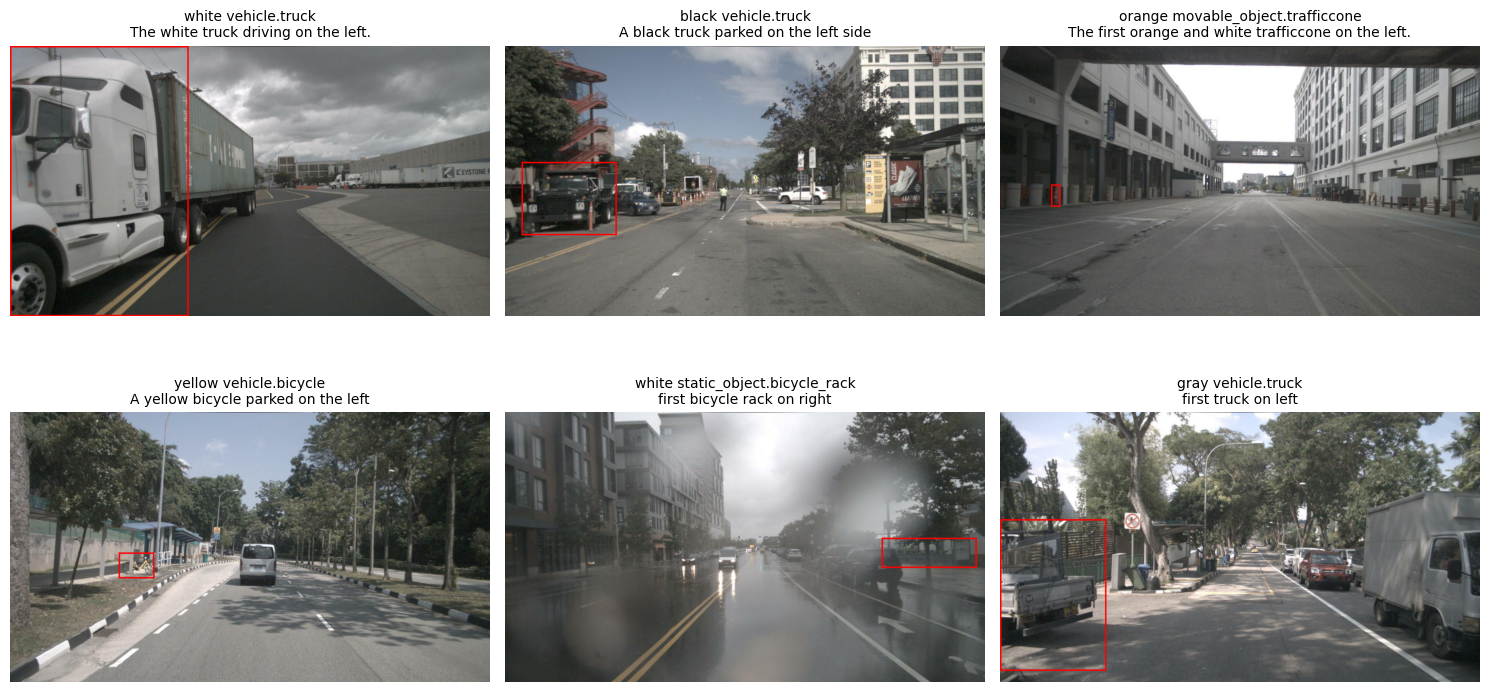

In [7]:
samples = random.Random(SEED+2).sample(train_candidates, min(6,len(train_candidates)))
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,r in zip(axs.flat,samples):
    with Image.open(IMAGES/r['img']) as f: im=f.convert('RGB')
    draw=ImageDraw.Draw(im)
    x,y,w,h=r['box']; draw.rectangle((x,y,x+w,y+h),outline='red',width=5)
    ax.imshow(im); ax.axis('off'); ax.set_title(f"{r['color']} {r['cls']}\n{r['description'][:55]}",fontsize=10)
plt.tight_layout();plt.show()


## A7 · Find additional objects without exhausting Colab RAM

Talk2Car-Expr labels one target. Use YOLO **only on the selected images**, two at a time, to estimate additional traffic objects. This is for *image patch placement*, never for truth labels or unverified CML negatives. Cache incremental results so a restarted scan can resume.

In [8]:
from ultralytics import YOLO

DETECTOR_FILE = 'yolov8n.pt'  # Small pre-trained YOLO model
ROAD_CLASSES = {0, 1, 2, 3, 5, 7, 9, 11}  # person, bicycle, car, bike, bus, truck, lights, signs
DETECTION_CACHE = OUT / 'yolo_boxes.json'
names = sorted({r['img'] for r in selected})
detections = json.loads(DETECTION_CACHE.read_text()) if DETECTION_CACHE.exists() else {}
missing_scan = [n for n in names if n not in detections]
print('YOLO images to scan:', len(missing_scan), '| cached:', len(names)-len(missing_scan))

if missing_scan:
    detector = YOLO(DETECTOR_FILE)
    for start in tqdm(range(0, len(missing_scan), 2), desc='YOLO: 2 images at a time'):
        batch_names = missing_scan[start:start + 2]
        paths = [str(IMAGES / name) for name in batch_names]
        # The list holds at most TWO image predictions, not thousands.
        preds = detector.predict(paths, device=0, imgsz=384, conf=0.30,
                                 batch=2, max_det=25, verbose=False)
        for name, pred in zip(batch_names, preds):
            found = []
            if pred.boxes is not None:
                for xy, cls in zip(pred.boxes.xyxy.cpu().tolist(),
                                   pred.boxes.cls.cpu().tolist()):
                    if int(cls) in ROAD_CLASSES:
                        found.append({'box': [float(v) for v in xy],
                                      'class_id': int(cls)})
            detections[name] = found
        del preds
        if (start//2 + 1) % 25 == 0:
            DETECTION_CACHE.write_text(json.dumps(detections))
            gc.collect()
    DETECTION_CACHE.write_text(json.dumps(detections))
    del detector
    gc.collect(); torch.cuda.empty_cache()

assert set(names).issubset(detections), 'YOLO scan incomplete; rerun this cell to resume.'
print('Number of road objects detected per image:',
      Counter(len(detections[n]) for n in names).most_common(8))

YOLO images to scan: 0 | cached: 608
Number of road objects detected per image: [(1, 115), (0, 112), (2, 95), (3, 87), (4, 51), (5, 48), (6, 37), (7, 25)]


## A8 · Keep images with **at least two distinct object boxes**

We merge the single official target box with detected boxes, removing obvious duplicates. Only images with ≥2 regions are kept. This does **not** prove there are two identical red cars; it proves two separately located object regions can be targeted. Print the actual count, since it may be below the 3,000 candidate target.

In [9]:
def xywh_to_xyxy(box):
    x,y,w,h=box
    return [x,y,x+w,y+h]

def iou(a,b):
    x1=max(a[0],b[0]); y1=max(a[1],b[1]); x2=min(a[2],b[2]); y2=min(a[3],b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    ua=max(0,a[2]-a[0])*max(0,a[3]-a[1]);ub=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/max(1e-8,ua+ub-inter)

def distinct_objects(row):
    chosen=[xywh_to_xyxy(row['box'])]  # Always retain the official target
    for found in detections.get(row['img'],[]):
        b = found['box']
        if b[2]<=b[0] or b[3]<=b[1]:continue
        if all(iou(b,v)<0.55 for v in chosen):chosen.append(b)
    return chosen

for r in selected:r['objects']=distinct_objects(r)
train_rows=[r for r in train_candidates if len(r['objects'])>=2 and min(r['box'][2:])>=12]
val_rows=[r for r in val_candidates if len(r['objects'])>=2 and min(r['box'][2:])>=12]
print('Usable multi-object scenes:',len(train_rows),'train /',len(val_rows),'validation')
print('Object counts:',Counter(min(len(r['objects']),5) for r in train_rows).most_common())
assert len(train_rows)>=20 and len(val_rows)>=10, 'Too few multi-object scenes. Inspect YOLO detections and box sizes.'
pd.DataFrame([{k:v for k,v in r.items() if k!='objects'} for r in train_rows]).to_csv(OUT/'train_manifest.csv',index=False)
pd.DataFrame([{k:v for k,v in r.items() if k!='objects'} for r in val_rows]).to_csv(OUT/'val_manifest.csv',index=False)
print('Train records containing two detected cars:',
      sum(sum(d['class_id']==2 for d in detections.get(r['img'],[]))>=2 for r in train_rows))


Usable multi-object scenes: 367 train / 71 validation
Object counts: [(5, 132), (3, 92), (2, 87), (4, 56)]
Train records containing two detected cars: 246


## A9 · Object patches and **meaningful text-token** masks

A 224×224 ViT-B/32 image has **49 image patches (7×7)**. We use the official target box and up to two YOLO-estimated neighbors to select SEPARATE patches per object. The dataloader preserves a [3,50] region mask so noisy training can verify that at least two different objects are affected. For text, we preferentially select CLIP BPE tokens corresponding to the annotation's **color, object class, action, and location** when those words occur in the referring expression. If none appears, we select two content tokens as a reported fallback; this is not a scene-graph parser. The dataloader opens only one image at a time (`num_workers=0`).

In [10]:
from torch.utils.data import Dataset, DataLoader
import open_clip

MEAN=np.array([0.48145466,0.4578275,0.40821073],dtype=np.float32)
STD=np.array([0.26862954,0.26130258,0.27577711],dtype=np.float32)

# Preserve every road object in the frame instead of CLIP's center-crop.
def letterbox(image):
    W,H=image.size
    scale=min(224/W,224/H)
    nw,nh=max(1,round(W*scale)),max(1,round(H*scale))
    left,top=(224-nw)//2,(224-nh)//2
    canvas=Image.new('RGB',(224,224),tuple(int(v*255) for v in MEAN))
    canvas.paste(image.resize((nw,nh),Image.Resampling.BICUBIC),(left,top))
    return canvas,(nw/W,nh/H,left,top)

def box_patches(box,geometry):
    sx,sy,px,py=geometry
    x0,y0,x1,y1=box
    x0=max(0,min(224,x0*sx+px));x1=max(0,min(224,x1*sx+px))
    y0=max(0,min(224,y0*sy+py));y1=max(0,min(224,y1*sy+py))
    if x1<=x0 or y1<=y0:return []
    # Use overlapping cells; prioritize those covering most box area.
    candidates=[]
    for r in range(7):
        for c in range(7):
            a=max(0,min(x1,(c+1)*32)-max(x0,c*32))
            b=max(0,min(y1,(r+1)*32)-max(y0,r*32))
            if a*b>0:candidates.append((a*b,r*7+c))
    return [idx for area,idx in sorted(candidates,reverse=True)]

def object_patch_masks(row, geometry):
    # One row of region_masks = patches belonging to ONE distinct object.
    # Region 0 is the official target; regions 1-2 come from YOLO.
    region_masks = torch.zeros(MAX_OBJECT_REGIONS, 50, dtype=torch.bool)
    used = set()
    region_count = 0
    for box in row['objects'][:MAX_OBJECT_REGIONS]:
        # Do not assign the same ViT patch to two different objects.
        patches = [p for p in box_patches(box, geometry) if p not in used][:4]
        if not patches:
            continue
        region_masks[region_count, [p + 1 for p in patches]] = True
        used.update(patches)
        region_count += 1
    combined = region_masks.any(dim=0)
    return combined, region_count, region_masks

def tokens_to_mask(text, row):
    """Mask meaningful color/object/action/location tokens where possible.

    CLIP words can occupy several BPE tokens. Find the corresponding token
    subsequence directly, instead of guessing word-token offsets.
    """
    ids = open_clip.tokenize([text])[0]
    end = int(ids.argmax().item())    # Stop at EOS, never corrupt BOS/EOS.
    content = list(range(1, end))
    flags = torch.zeros(77, dtype=torch.bool)
    if not content:
        return ids, flags

    typ = row['cls'].split('.')[1] if '.' in row['cls'] else row['cls']
    terms = [row['color'], typ, row['action'], row['location']]
    # e.g. 'the left red car' → mask the actual BPE tokens for red/car/left.
    meaningful = set()
    for term in terms:
        term = str(term).lower().strip()
        if not term or term == 'not applicable':
            continue
        part = open_clip.tokenize([term])[0]
        part_end = int(part.argmax().item())
        piece = part[1:part_end].tolist()
        if not piece:
            continue
        for pos in range(1, end - len(piece) + 1):
            if ids[pos:pos+len(piece)].tolist() == piece:
                meaningful.update(range(pos, pos+len(piece)))

    rng = random.Random(sum(ord(c) for c in text) + SEED)
    selected = sorted(meaningful)[:4]
    # Some descriptions lack explicitly matching color/class terms.
    # Keep 2 mask tokens in those cases, and report that as a fallback.
    if len(selected) < min(2, len(content)):
        other = [i for i in content if i not in selected]
        selected.extend(rng.sample(other, min(2-len(selected), len(other))))
    flags[selected] = True
    return ids, flags

class TrafficDataset(Dataset):
    def __init__(self,rows):self.rows=rows
    def __len__(self):return len(self.rows)
    def __getitem__(self,index):
        r=self.rows[index]
        with Image.open(IMAGES/r['img']) as f:source=f.convert('RGB')
        scene,geometry=letterbox(source)
        pix=np.asarray(scene,dtype=np.float32)/255
        scene_tensor=torch.from_numpy(((pix-MEAN)/STD).transpose(2,0,1).copy())
        x,y,w,h=r['box'];W,H=source.size
        x0,y0=max(0,min(W-1,int(x))),max(0,min(H-1,int(y)))
        x1,y1=max(x0+1,min(W,int(x+w))),max(y0+1,min(H,int(y+h)))
        target=source.crop((x0,y0,x1,y1))
        crop,_=letterbox(target)
        cpix=np.asarray(crop,dtype=np.float32)/255
        crop_tensor=torch.from_numpy(((cpix-MEAN)/STD).transpose(2,0,1).copy())
        image_mask, regions, region_masks = object_patch_masks(r, geometry)
        token_ids, text_mask = tokens_to_mask(r['description'], r)
        # Keep patches for EACH object, not just a combined patch mask.
        # B3 can then corrupt at least two distinct object regions.
        return {'scene':scene_tensor,'crop':crop_tensor,'tokens':token_ids,
                'image_mask':image_mask,'region_masks':region_masks,
                'text_mask':text_mask,
                'regions':regions,'cls':r['cls'],'color':r['color'],'img':r['img'],
                'id':r['id'],'split':r['split']}

# Filter only once: two distinct usable object patch regions.
# PIL header inspection avoids loading every image into memory.
def has_two_visual_regions(row):
    with Image.open(IMAGES / row['img']) as f:
        W, H = f.size
    scale = min(224/W, 224/H)
    nw, nh = max(1, round(W*scale)), max(1, round(H*scale))
    geometry = (nw/W, nh/H, (224-nw)//2, (224-nh)//2)
    flags, regions, _ = object_patch_masks(row, geometry)
    return regions >= 2 and flags.sum() >= 2

train_rows = [r for r in train_rows if has_two_visual_regions(r)]
val_rows = [r for r in val_rows if has_two_visual_regions(r)]
assert len(train_rows) >= 20 and len(val_rows) >= 10, 'Too few multi-region examples; inspect YOLO boxes.'
print('Verified multi-region scenes:',len(train_rows),'train /',len(val_rows),'val')
for split_name, rows in [('train',train_rows),('val',val_rows)]:
    pd.DataFrame([{k:v for k,v in r.items() if k!='objects'} for r in rows]).to_csv(
        OUT/f'{split_name}_manifest.csv', index=False)

train_set=TrafficDataset(train_rows)
val_set=TrafficDataset(val_rows)
train_loader=DataLoader(train_set,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=False,drop_last=True)
val_loader=DataLoader(val_set,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=False)
preview=next(iter(train_loader))
print('Image batch:',tuple(preview['scene'].shape),'visual mask:',tuple(preview['image_mask'].shape))
print('Text mask:',tuple(preview['text_mask'].shape))
print('Distinct object regions masked per example:',preview['regions'].tolist())
print('Masked visual patches:',preview['image_mask'].sum(1).tolist())
print('Patches per separate object:',preview['region_masks'].sum(2).tolist())
print('Masked text tokens:',preview['text_mask'].sum(1).tolist())
print('Filtered candidate images now used:',len(train_rows),'train,',len(val_rows),'validation')
print('Sample text:',train_rows[0]['description'])
assert (preview['image_mask'].sum(1)>0).all()
assert (preview['text_mask'].sum(1)>0).all()

Verified multi-region scenes: 344 train / 67 val
Image batch: (2, 3, 224, 224) visual mask: (2, 50)
Text mask: (2, 77)
Distinct object regions masked per example: [3, 3]
Masked visual patches: [4, 5]
Patches per separate object: [[2, 1, 1], [2, 2, 1]]
Masked text tokens: [2, 2]
Filtered candidate images now used: 344 train, 67 validation
Sample text: A white T-shirt adult man on the right


## A10 · Inspect actual image and text corruption before training

The figure highlights object-overlapping visual patches from at least two distinct regions. Below it, separate patch IDs for each object are printed. We also print the selected caption and text-token indices. The textual mask is annotation-guided where matches exist; if the description lacks the listed terms, it uses a small fallback rather than inventing attribute grounding.

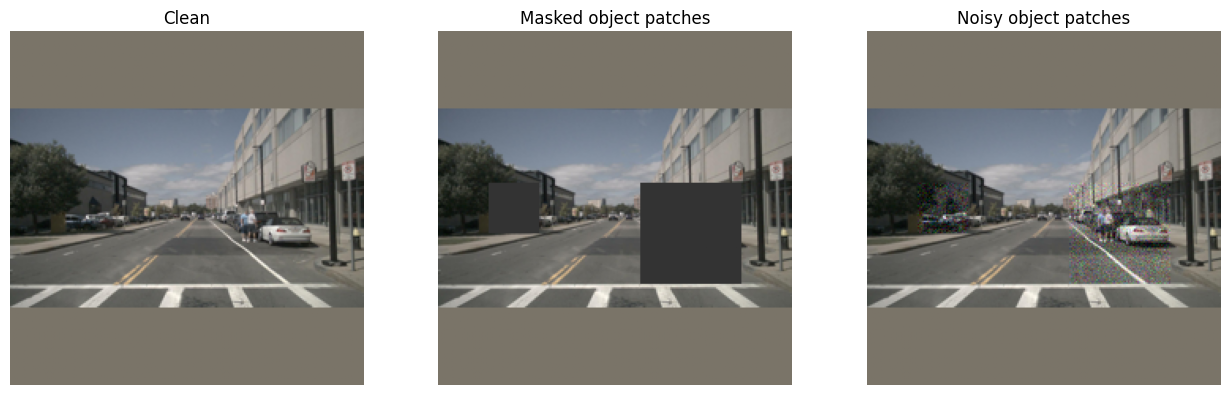

Actual description: A white T-shirt adult man on the right
Image patches affected: [22, 25, 26, 32, 33]
Text token indices affected: [2, 10]
Object regions represented: 3
Object-specific patch indices (0–48):
  Object 1: [25, 32]
  Object 2: [26, 33]
  Object 3: [22]


In [11]:
# Display one actual image in three forms BEFORE starting any model training.
example = train_set[0]
original = example['scene'].numpy().transpose(1, 2, 0)
clean = np.clip(original * STD + MEAN, 0, 1)
mask = clean.copy()
patch_ids = torch.where(example['image_mask'][1:])[0].tolist()
for patch in patch_ids:
    row, col = divmod(patch, 7)
    mask[row*32:(row+1)*32, col*32:(col+1)*32] = 0.2
noisy = clean.copy()
rng = np.random.default_rng(SEED)
for patch in patch_ids:
    row, col = divmod(patch, 7)
    sl = np.s_[row*32:(row+1)*32, col*32:(col+1)*32]
    noisy[sl] = np.clip(noisy[sl] + rng.normal(0, PIXEL_NOISE_SIGMA, noisy[sl].shape), 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, pic, label in zip(axes, [clean, mask, noisy], ['Clean', 'Masked object patches', 'Noisy object patches']):
    ax.imshow(pic); ax.set_title(label); ax.axis('off')
plt.tight_layout(); plt.show()
print('Actual description:', train_rows[0]['description'])
print('Image patches affected:', patch_ids)
print('Text token indices affected:', torch.where(example['text_mask'])[0].tolist())
print('Object regions represented:', example['regions'])
print('Object-specific patch indices (0–48):')
for i, region in enumerate(example['region_masks']):
    patches = (torch.where(region[1:])[0]).tolist()
    if patches:
        print(f'  Object {i+1}: {patches}')
assert example['regions'] >= 2, 'This should demonstrate multi-object masking.'


## A11 · Prepare a **manual CML negative review packet**

**Do not train yet.** For selected **official target crops** with supported color annotations, we propose one wrong-color caption. Each proposed negative requires human verification: check the full scene, target crop, *positive* description and *negative* description. A target crop can be too ambiguous to approve.

This cell creates a ZIP of labeled previews and an audit CSV with easy **integer `row_id` values**. Download the ZIP and inspect **every candidate**. In A12, enter the rejected row IDs into `REJECTED_ROW_IDS`, then explicitly set `REVIEWED_ALL = True` only after inspection. You do **not** need to upload the CSV again. Only approved training pairs contribute to CML; validation approvals are kept separate.


Manual review rows by split: {'train': 96, 'val': 24}
Generated preview JPGs: 120 | review packet: /content/macco_traffic_w1_cml/outputs/traffic_review_packet.zip


,row_id,split,img,target_color,positive_prompt,negative_prompt,approved
0,1,train,train_406.jpg,white,a photo of a white car,a photo of a maroon car,
1,2,train,train_8308.jpg,white,a photo of a white car,a photo of a maroon car,
2,3,train,train_5409.jpg,yellow,a photo of a yellow car,a photo of a brown car,
3,4,train,train_626.jpg,white,a photo of a white car,a photo of a maroon car,
4,5,train,train_1891.jpg,black,a photo of a black motorcycle,a photo of a blue motorcycle,
5,6,train,train_188.jpg,black,a photo of a black car,a photo of a blue car,
6,7,train,train_7564.jpg,yellow,a photo of a yellow car,a photo of a brown car,
7,8,train,train_2167.jpg,gray,a photo of a gray car,a photo of an orange car,


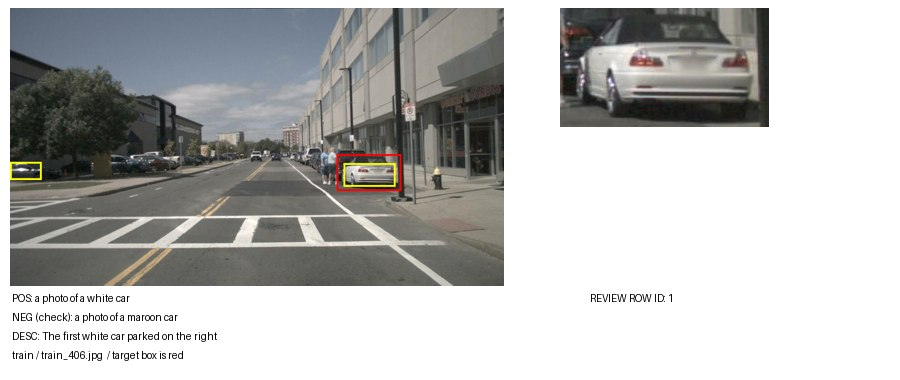

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Generate the review set from our FINAL filtered train/validation rows.
# No model training happens in this cell.
from PIL import ImageFont

COLOR_POOL = ['black','white','red','gray','yellow','blue',
              'maroon','beige','orange','brown','green','pink']
ROAD_NAMES = {'vehicle.car':'car','vehicle.truck':'truck',
              'vehicle.bus.rigid':'bus','vehicle.bus.bendy':'bus',
              'vehicle.motorcycle':'motorcycle','vehicle.bicycle':'bicycle'}

def object_name(raw):
    return ROAD_NAMES.get(raw, raw.rsplit('.',1)[-1].replace('_',' '))

def eligible_for_color_review(row):
    return (row['cls'].startswith('vehicle.') and
            row['color'].lower().strip() in COLOR_POOL)

def pick_review_rows(rows, limit, offset):
    eligible = [r for r in rows if eligible_for_color_review(r)]
    return random.Random(SEED + offset).sample(eligible, min(limit, len(eligible)))

review_rows = []
review_dir = OUT / 'traffic_review_previews'
review_dir.mkdir(exist_ok=True)
for split, rows, maximum, offset in [
    ('train', train_rows, REVIEW_TRAIN, 100),
    ('val', val_rows, REVIEW_VAL, 200)
]:
    for row in pick_review_rows(rows, maximum, offset):
        color = row['color'].lower().strip()
        typ = object_name(row['cls'])
        # Deterministic PROPOSED color change; not approved without review.
        wrong = COLOR_POOL[(COLOR_POOL.index(color) + 5) % len(COLOR_POOL)]
        pos_article = 'an' if color[0] in 'aeiou' else 'a'
        neg_article = 'an' if wrong[0] in 'aeiou' else 'a'
        pos_prompt = f'a photo of {pos_article} {color} {typ}'
        neg_prompt = f'a photo of {neg_article} {wrong} {typ}'
        review_id = len(review_rows) + 1  # Human-friendly ID to use in A12
        preview_name = f"{review_id:03d}_{split}_{row['id'][:12]}.jpg"
        preview_path = review_dir / preview_name
        with Image.open(IMAGES / row['img']) as opened:
            full = opened.convert('RGB')
        x,y,w,h = row['box']
        x0,y0,x1,y1 = int(max(0,x)), int(max(0,y)), int(min(full.width,x+w)), int(min(full.height,y+h))
        if x1 <= x0 or y1 <= y0:
            continue
        target = full.crop((x0,y0,x1,y1))
        scene = full.copy()
        draw = ImageDraw.Draw(scene)
        # Yellow = additional detected objects
        for box in row['objects'][1:3]:
              draw.rectangle(box, outline='yellow', width=6)
        # Red = official target object used for CML
        draw.rectangle((x0, y0, x1, y1), outline='red', width=6)
        # One straightforward preview: highlighted whole image + enlarged target.
        page = Image.new('RGB', (900,380), 'white')
        scene.thumbnail((540,278)); target.thumbnail((310,278))
        page.paste(scene, (10,8)); page.paste(target, (560,8))
        draw = ImageDraw.Draw(page)
        draw.text((590,292), f'REVIEW ROW ID: {review_id}', fill='black')
        draw.text((12,292), f'POS: {pos_prompt}', fill='black')
        draw.text((12,311), f'NEG (check): {neg_prompt}', fill='black')
        draw.text((12,330), f'DESC: {row["description"][:105]}', fill='black')
        draw.text((12,349), f'{split} / {row["img"]}  / target box is red', fill='black')
        page.save(preview_path, quality=87)
        review_rows.append({
            'row_id': review_id, 'id':row['id'], 'split':split, 'img':row['img'],
            'description':row['description'], 'class':row['cls'],
            'target_color':color, 'negative_color':wrong,
            'positive_prompt':pos_prompt, 'negative_prompt':neg_prompt,
            'preview':preview_name, 'approved':'', 'review_notes':''
        })

review = pd.DataFrame(review_rows)
assert not review.empty, 'No valid color-labelled vehicle examples to review.'
assert review[['split','id']].duplicated().sum() == 0
REVIEW_TEMPLATE = OUT / 'traffic_candidates_for_review.csv'
review.to_csv(REVIEW_TEMPLATE, index=False)
# The ZIP includes both the editable CSV and the preview images.
PACKET_BASE = OUT / 'traffic_review_packet'
PACKET = Path(shutil.make_archive(str(PACKET_BASE),'zip',OUT,
    base_dir='traffic_review_previews'))
with zipfile.ZipFile(PACKET,'a') as z:
    z.write(REVIEW_TEMPLATE, arcname='traffic_candidates_for_review.csv')

print('Manual review rows by split:',review['split'].value_counts().to_dict())
print('Generated preview JPGs:',len(review),'| review packet:',PACKET)
display(review[['row_id','split','img','target_color','positive_prompt',
                'negative_prompt','approved']].head(8))
from IPython.display import display as show
show(Image.open(review_dir / review.iloc[0]['preview']))
# Download ZIP and inspect every image. In A12, enter only rejected row IDs.
from google.colab import files
files.download(str(PACKET))

## A12 · Approve reviewed captions **inside Colab** (mandatory before training)

After downloading the A11 ZIP, inspect **every numbered preview**. The positive caption must describe the **highlighted target crop** correctly and the proposed negative must be **false for that same target crop**. Reject any ambiguous color, incorrect target, confusing crop, or questionable negative.

**You don't need to upload a CSV.** Enter the integers printed on the preview images in `REJECTED_ROW_IDS`. When you have inspected **all** the images, change `REVIEWED_ALL = False` to `True` and run this cell. It saves `human_reviewed_cml.csv`, reports approved/rejected counts, and prepares `APPROVED_TRAIN` and `APPROVED_VAL` for later cells.

This cell **does not approve anything by default**. Setting `REVIEWED_ALL=True` is your explicit confirmation, not an automatic verification; please only do that after you review every image.


In [14]:
#@title A12 · Approve the CML captions you personally reviewed
# 1) Inspect every numbered preview in the A11 ZIP first.
# 2) Put row IDs that are WRONG / AMBIGUOUS / UNCERTAIN here.
REJECTED_ROW_IDS = [5,14,33,39,50,67,75,100,109]      # Example: [3, 14, 27]

# 3) Keep False until you have reviewed ALL candidates.
REVIEWED_ALL = True       # Change to True ONLY after reviewing all previews.

# The audit was generated in A11; no upload is needed.
AUDIT = REVIEW_TEMPLATE
reviewed = pd.read_csv(AUDIT, dtype=str).fillna('')

required_cols = ['row_id', 'id', 'split', 'img', 'target_color',
                 'negative_color', 'positive_prompt', 'negative_prompt']
assert set(required_cols).issubset(reviewed.columns), 'Missing columns in audit CSV.'
assert REVIEWED_ALL is True, (
    'First review EVERY image from A11, enter rejected row IDs, '
    'then set REVIEWED_ALL=True.')
assert all(type(x) is int for x in REJECTED_ROW_IDS), 'Use integer row IDs, e.g. [3, 14].'
assert len(set(REJECTED_ROW_IDS)) == len(REJECTED_ROW_IDS), 'Repeated rejected row ID.'

reviewed['row_id'] = pd.to_numeric(reviewed['row_id'], errors='raise').astype(int)
assert reviewed['row_id'].is_unique, 'Duplicate row IDs in audit file.'

# Check we are approving EXACTLY the current preview packet, with no edited prompts.
expected = review.copy()
expected['row_id'] = expected['row_id'].astype(int)
assert len(reviewed) == len(expected), 'Audit row count changed. Rerun A11.'
assert set(reviewed['row_id']) == set(expected['row_id']), 'Unknown/missing audit row IDs.'
for field in ['id','split','img','target_color','negative_color',
              'positive_prompt','negative_prompt']:
    actual = reviewed.set_index('row_id')[field].sort_index().astype(str)
    original = expected.set_index('row_id')[field].sort_index().astype(str)
    assert actual.equals(original), f'Audit {field} changed. Rerun A11.'

available_ids = set(reviewed['row_id'])
assert set(REJECTED_ROW_IDS) <= available_ids, (
    f'Unknown rejected row IDs: {sorted(set(REJECTED_ROW_IDS) - available_ids)}')

# A candidate is approved only because the human reviewer has confirmed all previews.
has_candidate = reviewed['negative_prompt'].astype(str).str.strip().ne('')
reviewed['approved'] = np.where(
    has_candidate & ~reviewed['row_id'].isin(REJECTED_ROW_IDS), 'yes', 'no')

# Train/validation decisions are kept separate; later CML never uses rejected rows.
approved = reviewed.loc[reviewed['approved'] == 'yes'].copy()
train_approved = approved.loc[approved['split'] == 'train'].copy()
val_approved = approved.loc[approved['split'] == 'val'].copy()
print('Total candidates:', len(reviewed))
print('Approved training negatives:', len(train_approved))
print('Approved validation negatives:', len(val_approved))
print('Rejected / unavailable:', int((reviewed['approved'] == 'no').sum()))

# These are minimum experiment sizes, NOT reasons to approve uncertain examples.
assert len(train_approved) >= 10 and len(val_approved) >= 5, (
    'Too few verified pairs. Generate/review more candidates; do not approve doubtful pairs.')

APPROVED_BY_KEY = {(r['split'],r['id']):r for _,r in approved.iterrows()}
APPROVED_TRAIN = {key:r for key,r in APPROVED_BY_KEY.items() if key[0] == 'train'}
APPROVED_VAL = {key:r for key,r in APPROVED_BY_KEY.items() if key[0] == 'val'}

# Write BOTH the original audit and explicit decisions so the review is reproducible.
REVIEWED_AUDIT = OUT / 'human_reviewed_cml.csv'
reviewed.to_csv(REVIEWED_AUDIT, index=False)
print('CML review saved:', REVIEWED_AUDIT)
print('PASS: Only approved negatives will contribute to CML.')


Total candidates: 120
Approved training negatives: 89
Approved validation negatives: 22
Rejected / unavailable: 9
CML review saved: /content/macco_traffic_w1_cml/outputs/human_reviewed_cml.csv
PASS: Only approved negatives will contribute to CML.


## B1 · Fetch the **official MACCO source** and patch text masking for noise mode

The reconstruction heads and **original four-loss function** are imported from the authors' code. The one limited source edit adds a *second* text-corruption mode: Gaussian noise on selected text embeddings. Mask mode remains unchanged. We also fix the authors' dynamic-method binding for Colab/Python compatibility.

In [15]:
AUTHOR = WORK / 'MACCO'
if not (AUTHOR / '.git').exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--no-checkout',
                    'https://github.com/hiker-lw/MACCO.git', str(AUTHOR)], check=True)
if not (AUTHOR / 'src/open_clip_code/MACCO_variant/MACCO_text_image.py').exists():
    subprocess.run(['git', '-C', str(AUTHOR), 'sparse-checkout', 'set', '--no-cone', '/src/'], check=True)
    subprocess.run(['git', '-C', str(AUTHOR), 'checkout', 'HEAD'], check=True)
sys.path.insert(0, str(AUTHOR / 'src'))

source_file = AUTHOR / 'src/open_clip_code/MACCO_variant/MACCO_text_image.py'
source = source_file.read_text()
# The released author's method binding needs this Python compatibility fix.
for name, obj in [('clip_encode_text','self.CLIP'), ('clip_encode_image','self.CLIP'),
                  ('clip_vit_forward','self.CLIP.visual'), ('clip_forward','self.CLIP')]:
    old = f'self.{name}.__get__({obj})'
    new = f'type(self).{name}.__get__({obj}, type({obj}))'
    if old in source:
        source = source.replace(old, new, 1)
    else:
        assert new in source, f'Unexpected upstream method definition: {name}'

# Extend only the masked TEXT branch: replace token masking with embedding noise on noise batches.
original_mask = ('        x_full_mask = x_full_mask * (~key_mask[:, :, None]) + '
                 + chr(92) + '\n'
                 + '                text_mask_token[None, None, :] * key_mask[:, :, None]')
replacement = """        mode = getattr(self, 'text_corruption_mode', 'mask')
        if mode == 'noise':
            sigma = float(getattr(self, 'text_noise_strength', 0.0))
            std = x_full_mask.detach().float().std().clamp_min(1e-6).to(x_full_mask.dtype)
            x_full_mask = x_full_mask + sigma * std * torch.randn_like(x_full_mask) * key_mask.unsqueeze(-1)
        elif mode == 'mask':
            x_full_mask = x_full_mask * (~key_mask[:, :, None]) + (text_mask_token[None, None, :] * key_mask[:, :, None])
        else:
            raise ValueError(f'Invalid text corruption mode: {mode}')"""
if 'text_corruption_mode' not in source:
    assert source.count(original_mask) == 1, 'Author text-mask code changed; inspect before editing.'
    source = source.replace(original_mask, replacement, 1)
source_file.write_text(source)
compile(source, str(source_file), 'exec')
commit = subprocess.check_output(['git', '-C', str(AUTHOR), 'rev-parse', 'HEAD'], text=True).strip()
print('Official MACCO commit:', commit)
print('Compatible masking/noise branch installed in Colab copy.')


Official MACCO commit: 97fbae1416e30eba84cc0b8209d9cb6bdedfe6ae
Compatible masking/noise branch installed in Colab copy.


## B2 · Load **our W1+CML encoder** and initialize new official predictors

The released CLIP-only checkpoint has no predictor weights. We instantiate the authors' `MACCO_CLIP_text_image` wrapper, which creates a new image predictor, text predictor, and learnable mask tokens. We **do not** claim the new heads are already trained.

In [16]:
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from training.params import parse_args
from open_clip_code import create_model_and_transforms, tokenize
from open_clip_code.MACCO_variant.MACCO_text_image import MACCO_CLIP_text_image
from open_clip_code.loss_fn.MACCO_CLIP_loss_text_image_raw_space import macco_clip_loss_text_image
import yaml

settings=yaml.safe_load((AUTHOR/'src/config/MACCO_CLIP.yaml').read_text())
saved_argv=sys.argv[:]
try:
    sys.argv=[sys.argv[0],'--model','ViT-B-32']
    args=parse_args()
finally:sys.argv=saved_argv
for key,value in settings.items():setattr(args,key,value)
args.model='ViT-B-32'
args.contrast_loss_w=W_CONTRAST
args.intra_modal_contrast_loss_w=W_INTRA
args.mask_text_loss_w=W_TEXT_RECON
args.mask_image_loss_w=W_IMAGE_RECON

try:
    from google.colab import userdata
    token=userdata.get('HF_TOKEN')
except Exception:token=None
ckpt=hf_hub_download(repo_id=HF_REPO,filename=HF_FILE,token=token)
base_clip,_,_=create_model_and_transforms('ViT-B-32',pretrained=ckpt,device='cpu',precision='fp32')
model=MACCO_CLIP_text_image(base_clip,args).to(DEVICE)
criterion=macco_clip_loss_text_image(args)
AMP_DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
model.CLIP.text_corruption_mode='mask'
model.CLIP.text_noise_strength=0.0
print('Loaded YOUR checkpoint:',HF_FILE)
print('New image predictor parameters:',sum(p.numel() for p in model.prediction_image.parameters()))
print('New text predictor parameters:',sum(p.numel() for p in model.prediction_text.parameters()))
print('W1 original MACCO loss weights:',[W_CONTRAST,W_INTRA,W_TEXT_RECON,W_IMAGE_RECON])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:121: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


MACCO-W1-CML-ViT-B-32.pt: reconstructing file:   0%|          |  0.00B /  605MB            

MACCO-W1-CML-ViT-B-32.pt: downloading bytes:           |  0.00B            

Loaded YOUR checkpoint: MACCO-W1-CML-ViT-B-32.pt
New image predictor parameters: 11325952
New text predictor parameters: 31654144
W1 original MACCO loss weights: [1.0, 0.2, 25.0, 250.0]


## B3 · **Only human-approved** CML negatives, plus separate image masking/noise

CML compares the **official target crop** against the specific positive and incorrect-color prompts you approved in A12. In image noise mode, masking and noise are assigned per OBJECT region, not by splitting one flattened list of patches. The model never trains CML on automatically generated but unapproved negatives. Other traffic examples still train using the **four original MACCO losses**. For noise-mode batches, some object patches are masked while *different* patches are given Gaussian noise; they never overlap.

In [17]:
# CML needs A12 to have finished. It does NOT invent/approve negatives here.
assert APPROVED_TRAIN and APPROVED_VAL, 'Complete the manual CML review first.'

@torch.no_grad()
def frozen_text_embeddings(prompts):
    ids=tokenize(prompts).to(DEVICE)
    zeros=torch.zeros_like(ids,dtype=torch.bool)
    vec,*_=model.CLIP.encode_text(ids,zeros,model.text_mask_token)
    return F.normalize(vec.float(),dim=-1)

# Cache only reviewed, accepted prompts. Text tower stays frozen for this pilot.
PROMPT_EMB = {}
for item in approved.to_dict('records'):
    for field in ('positive_prompt','negative_prompt'):
        prompt = item[field]
        if prompt not in PROMPT_EMB:
            PROMPT_EMB[prompt] = frozen_text_embeddings([prompt])[0].detach()
print('Cached approved prompt embeddings:',len(PROMPT_EMB))

def pixel_noise_in_object_patches(images,patch_flags,sigma=PIXEL_NOISE_SIGMA):
    # image tensor is CLIP-normalized; unnormalize before RGB noise.
    mean=torch.tensor(MEAN,device=images.device).view(1,3,1,1)
    std=torch.tensor(STD,device=images.device).view(1,3,1,1)
    rgb=(images*std+mean).clamp(0,1)
    grid=patch_flags[:,1:].reshape(-1,7,7)
    pix_mask=grid.repeat_interleave(32,1).repeat_interleave(32,2)[:,None]
    noise=torch.randn_like(rgb)*sigma
    rgb_corrupt=(rgb+pix_mask*noise).clamp(0,1)
    return (rgb_corrupt-mean)/std

def separate_image_masks(region_masks):
    """Corrupt EACH object's patches, not alternating a flattened patch list.

    Input: [batch, max_objects, 50], one mask per distinct object.
    For objects spanning 2+ patches, mask some patches and noise others.
    For a 1-patch object, alternate mask/noise by object so both are used.
    In either case, >=2 distinct objects are visibly affected per example.
    """
    batch_size = region_masks.shape[0]
    masks = torch.zeros((batch_size, 50), dtype=torch.bool,
                        device=region_masks.device)
    noises = torch.zeros_like(masks)
    for b in range(batch_size):
        count = 0
        for region in region_masks[b]:
            patches = torch.where(region)[0]
            if patches.numel() == 0:
                continue
            if patches.numel() >= 2:
                masks[b, patches[::2]] = True
                noises[b, patches[1::2]] = True
            elif count % 2 == 0:
                masks[b, patches] = True
            else:
                noises[b, patches] = True
            count += 1
        assert count >= 2, 'Each training row must contain two usable objects.'
    assert not (masks & noises).any(), 'A patch cannot be masked and noised.'
    assert (masks.sum(1) > 0).all() and (noises.sum(1) > 0).all()
    return masks, noises

def cml_on_target_crops(batch):
    """Mean CML penalty for APPROVED training examples in this batch only."""
    valid = [(i, APPROVED_TRAIN[('train',uid)])
             for i,uid in enumerate(batch['id']) if ('train',uid) in APPROVED_TRAIN]
    if not valid:
        # Important: zero CML on unapproved examples, not invented targets.
        return next(model.parameters()).sum()*0.0, 0
    crop = batch['crop'][[i for i,_ in valid]].to(DEVICE)
    B = len(crop)
    empty = torch.zeros(B,50,device=DEVICE,dtype=torch.bool)
    feat,*_ = model.CLIP.encode_image(crop,empty,model.img_mask_token)
    feat = F.normalize(feat.float(),dim=-1)
    losses = []
    for j,(_,r) in enumerate(valid):
        pos = PROMPT_EMB[r['positive_prompt']]
        neg = PROMPT_EMB[r['negative_prompt']]
        losses.append(F.relu(CML_MARGIN + feat[j].dot(neg) - feat[j].dot(pos)))
    return torch.stack(losses).mean(), len(losses)

Cached approved prompt embeddings: 32


## B4 · Smoke test: one batch and **all four author losses**

This is the most important gate before training. Check image/text mask shapes, losses are finite, and the forward/backward pass fits in GPU memory. If it fails, **do not launch the training loops**.

In [18]:
batch = next(iter(train_loader))
model.eval()
clean = batch['scene'].to(DEVICE)
text = batch['tokens'].to(DEVICE)
all_patches = batch['image_mask'].to(DEVICE)
text_flags = batch['text_mask'].to(DEVICE)

with torch.autocast('cuda', dtype=torch.float16):
    # MASK: original author four-loss pipeline.
    model.CLIP.text_corruption_mode = 'mask'
    masked_output = model(clean, text, all_patches, text_flags)
    masked_loss = criterion(masked_output)
    # NOISE: actual noisy pixels are NOT covered by image mask tokens.
    mask_flags, noise_flags = separate_image_masks(batch['region_masks'].to(DEVICE))
    noisy_images = pixel_noise_in_object_patches(clean, noise_flags)
    model.CLIP.text_corruption_mode = 'noise'
    model.CLIP.text_noise_strength = 0.15
    noisy_output = model(noisy_images, text, mask_flags, text_flags)
    noisy_output['target_image'] = clean
    noisy_loss = criterion(noisy_output)

print('Mask-mode original losses:', {k: round(float(v.detach().cpu()),3) for k,v in masked_loss.items()})
print('Noise-mode original losses:', {k: round(float(v.detach().cpu()),3) for k,v in noisy_loss.items()})
print('Mask/noise visual patches:', mask_flags.sum(1).tolist(), noise_flags.sum(1).tolist())
# Verify that at least two SEPARATE objects have been affected (not two patches in one car).
regions = batch['region_masks'].to(DEVICE)
affected_regions = (regions & (mask_flags | noise_flags).unsqueeze(1)).any(dim=2).sum(dim=1)
print('Distinct objects affected per example:', affected_regions.tolist())
assert (affected_regions >= 2).all(), 'Multi-object corruption failed.'
assert all(torch.isfinite(v).all().item() for v in list(masked_loss.values()) + list(noisy_loss.values()))
assert (mask_flags & noise_flags).sum() == 0
assert (noisy_images-clean).abs().sum() > 0, 'No pixel noise reached the actual images.'
print('PASS: four author losses + separate visual mask/noise + text noise.')
del masked_output, noisy_output, masked_loss, noisy_loss
model.CLIP.text_corruption_mode = 'mask'
model.CLIP.text_noise_strength = 0.0
torch.cuda.empty_cache()


Mask-mode original losses: {'contrast_loss': 0.982, 'intra_modal_contrast_loss': 0.054, 'mask_loss_text': 10.857, 'mask_loss_image': 0.999, 'total_loss': 522.203}
Noise-mode original losses: {'contrast_loss': 1.253, 'intra_modal_contrast_loss': 0.0, 'mask_loss_text': 10.854, 'mask_loss_image': 1.0, 'total_loss': 522.605}
Mask/noise visual patches: [3, 3] [1, 4]
Distinct objects affected per example: [3, 3]
PASS: four author losses + separate visual mask/noise + text noise.


## B5 · Stage 1: warm up **new reconstruction heads**, encoder frozen

The encoder was already fine-tuned by you. Freezing it here prevents random predictor weights from immediately modifying existing W1+CML knowledge. **Only** the new image and text reconstruction predictors update. We also freeze mask tokens during this short stage to reduce memory; they become trainable in Stage 2. During this stage we use the authors' original four-loss objective. A short warm-up is an engineering compromise, not proof of converged reconstruction heads.

In [19]:
for p in model.CLIP.parameters():p.requires_grad_(False)
for p in model.prediction_text.parameters():p.requires_grad_(True)
for p in model.prediction_image.parameters():p.requires_grad_(True)
# Keep mask tokens frozen only during the short head warm-up to reduce GPU usage.
model.text_mask_token.requires_grad_(False)
model.img_mask_token.requires_grad_(False)

head_params=[p for p in model.parameters() if p.requires_grad]
optimizer=torch.optim.AdamW(head_params,lr=LR_HEADS,weight_decay=0.01)
scaler=torch.amp.GradScaler('cuda',enabled=(AMP_DTYPE==torch.float16))
model.CLIP.text_corruption_mode='mask'
model.CLIP.text_noise_strength=0.0
model.train()
optimizer.zero_grad(set_to_none=True)
warm_history=[]
max_steps=min(HEAD_WARMUP_BATCHES,len(train_loader))
for step,batch in enumerate(tqdm(train_loader,total=max_steps,desc='Head warm-up')):
    if step>=max_steps:break
    im=batch['scene'].to(DEVICE);tx=batch['tokens'].to(DEVICE)
    iflags=batch['image_mask'].to(DEVICE);tflags=batch['text_mask'].to(DEVICE)
    with torch.autocast('cuda',dtype=AMP_DTYPE):
        out=model(im,tx,iflags,tflags)
        parts=criterion(out)
        loss=parts['total_loss']/min(GRAD_ACCUM,max_steps-(step//GRAD_ACCUM)*GRAD_ACCUM)
    assert torch.isfinite(loss), 'Non-finite warm-up loss.'
    scaler.scale(loss).backward()
    if (step+1)%GRAD_ACCUM==0 or step+1==max_steps:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(head_params,1.0)
        scaler.step(optimizer);scaler.update();optimizer.zero_grad(set_to_none=True)
    warm_history.append(float(parts['total_loss'].detach().cpu()))
print('Warm-up steps:',len(warm_history),'| first/last loss:',round(warm_history[0],3),round(warm_history[-1],3))
full_warm=OUT/'W1_CML_Traffic_FULL_heads_warmup.pt'
torch.save({'state_dict':model.state_dict(),'stage':'heads_warmup','author_commit':commit},full_warm)
print('Saved full warm-up checkpoint:',full_warm)

Head warm-up:   0%|          | 0/40 [00:00<?, ?it/s]

Warm-up steps: 40 | first/last loss: 521.507 474.929
Saved full warm-up checkpoint: /content/macco_traffic_w1_cml/outputs/W1_CML_Traffic_FULL_heads_warmup.pt


## B6 · Baseline on **human-verified** held-out target-crop captions

Evaluate only `approved = yes` examples from the official validation split. This checks whether each target crop matches the reviewed correct prompt more strongly than the reviewed incorrect one. Evaluate both clean and noisy crops, with fixed noise seeds. It's an **internal traffic diagnostic**, not Table 1/21 accuracy.

In [20]:
@torch.no_grad()
def validate_color(model, sigma=0.0):
    """Accuracy on human-approved validation target crop pairs only."""
    model.eval()
    total = hits = 0
    for step,batch in enumerate(val_loader):
        matches = [(i, APPROVED_VAL[('val',uid)]) for i,uid in enumerate(batch['id'])
                   if ('val',uid) in APPROVED_VAL]
        if not matches:
            continue
        crops = batch['crop'][[i for i,_ in matches]].to(DEVICE)
        if sigma > 0:
            # Consistent noise by validation batch index, before vs after.
            flags = torch.ones(crops.shape[0],50,dtype=torch.bool,device=DEVICE)
            flags[:,0] = False
            with torch.random.fork_rng(devices=[torch.cuda.current_device()]):
                torch.manual_seed(SEED + 1000 + step)
                crops = pixel_noise_in_object_patches(crops,flags,sigma=sigma)
        zeros = torch.zeros(crops.size(0),50,dtype=torch.bool,device=DEVICE)
        embeddings,*_ = model.CLIP.encode_image(crops,zeros,model.img_mask_token)
        features = F.normalize(embeddings.float(),dim=-1)
        for j,(_,r) in enumerate(matches):
            pos,neg = PROMPT_EMB[r['positive_prompt']], PROMPT_EMB[r['negative_prompt']]
            hits += int(features[j].dot(pos) > features[j].dot(neg))
            total += 1
    assert total == len(APPROVED_VAL), 'Not all reviewed validation examples were evaluated.'
    return {'n':total,'accuracy':100*hits/total}

before_clean = validate_color(model, sigma=0)
before_noisy = validate_color(model, sigma=PIXEL_NOISE_SIGMA)
print('Before adaptation — clean:',before_clean)
print('Before adaptation — noisy:',before_noisy)

Before adaptation — clean: {'n': 22, 'accuracy': 90.9090909090909}
Before adaptation — noisy: {'n': 22, 'accuracy': 90.9090909090909}


## B7 · Continue training with **official four MACCO losses + reviewed CML + consistency**

Keep the originally trained W1+CML text tower frozen, train selected last visual blocks plus the new reconstruction heads. **CML applies only to approved training examples**, not every minibatch; `cml_batches` counts how many batches contained at least one approved example. Mask and noise corrupt different visual patches. This is a small controlled pilot, not a full original-MACCO reproduction.

In [26]:
# Freeze everything, then selectively train exactly the intended parameters.
for p in model.CLIP.parameters():p.requires_grad_(False)
for block in model.CLIP.visual.transformer.resblocks[-2:]:
    for p in block.parameters():p.requires_grad_(True)
for p in model.CLIP.visual.ln_post.parameters():p.requires_grad_(True)
model.CLIP.visual.proj.requires_grad_(True)
model.CLIP.visual.class_embedding.requires_grad_(False)
for p in model.prediction_text.parameters():p.requires_grad_(True)
for p in model.prediction_image.parameters():p.requires_grad_(True)
model.img_mask_token.requires_grad_(True)
model.text_mask_token.requires_grad_(True)

visual=[p for p in model.CLIP.parameters() if p.requires_grad]
heads=[p for n,p in model.named_parameters() if not n.startswith('CLIP.') and p.requires_grad]
optimizer=torch.optim.AdamW([{'params':visual,'lr':LR_VISUAL},
                             {'params':heads,'lr':LR_HEADS}],weight_decay=0.01)
scaler=torch.amp.GradScaler('cuda',enabled=(AMP_DTYPE==torch.float16))
print('Trainable visual params:',sum(p.numel() for p in visual))
print('Trainable predictor/mask params:',sum(p.numel() for p in heads))

history=[]
steps_per_epoch=min(len(train_loader),MAX_ADAPT_BATCHES or len(train_loader))
for epoch in range(1,ADAPT_EPOCHS+1):
    model.train();optimizer.zero_grad(set_to_none=True)
    sums=Counter(); valid_cml_batches=0; noise_batches=0
    for step,batch in enumerate(tqdm(train_loader,total=steps_per_epoch,desc=f'Adapt {epoch}/{ADAPT_EPOCHS}')):
        if step>=steps_per_epoch:break
        clean=batch['scene'].to(DEVICE)
        texts=batch['tokens'].to(DEVICE)
        imask=batch['image_mask'].to(DEVICE)
        tmask=batch['text_mask'].to(DEVICE)
        use_noise=random.random()>=MASK_MODE_PROB
        model.CLIP.text_corruption_mode='noise' if use_noise else 'mask'
        model.CLIP.text_noise_strength=0.15 if use_noise else 0.0
        if use_noise:
            model_masks, noise_patches = separate_image_masks(batch['region_masks'].to(DEVICE))
            images = pixel_noise_in_object_patches(clean, noise_patches)
        else:
            model_masks, images = imask, clean
        with torch.autocast('cuda',dtype=AMP_DTYPE):
            out=model(images,texts,model_masks,tmask)
            out['target_image']=clean  # Reconstruct ORIGINAL clean pixels, not noisy pixels.
            parts=criterion(out)       # Authors' four MACCO loss components.
            cml, cml_count = cml_on_target_crops(batch)  # Only human-approved examples.
            valid_cml_batches += int(cml_count > 0)
            consistency=out['img_feat_cls_token'].sum()*0.0
            if use_noise:
                # Clean reference has no gradient; noisy student remains trainable.
                zeros=torch.zeros_like(imask)
                with torch.no_grad():
                    clean_feat,*_=model.CLIP.encode_image(clean,zeros,model.img_mask_token)
                    clean_feat=F.normalize(clean_feat.float(),dim=-1).detach()
                student=F.normalize(out['img_feat_cls_token'].float(),dim=-1)
                consistency=(1-F.cosine_similarity(student,clean_feat,dim=-1)).mean()
                noise_batches+=1
            total=parts['total_loss']+W_CML*cml+W_NOISE*consistency
            win=min(GRAD_ACCUM,steps_per_epoch-(step//GRAD_ACCUM)*GRAD_ACCUM)
            loss=total/win
        if not torch.isfinite(loss):raise RuntimeError('Non-finite training loss; stop and inspect.')
        scaler.scale(loss).backward()
        if (step+1)%GRAD_ACCUM==0 or (step+1)==steps_per_epoch:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(visual+heads,1.0)
            scaler.step(optimizer);scaler.update();optimizer.zero_grad(set_to_none=True)
            with torch.no_grad():model.CLIP.logit_scale.clamp_(0,math.log(100))
        for k,v in [('total',total),('macco',parts['total_loss']),('cml',cml),('noise_consistency',consistency)]:
            sums[k]+=float(v.detach().cpu())
    record={'epoch':epoch,'steps':steps_per_epoch,'noise_batches':noise_batches,
            'cml_batches':valid_cml_batches,
            **{k:round(v/steps_per_epoch,4) for k,v in sums.items()}}
    history.append(record)
    display(pd.DataFrame([record]))
    full_path=OUT/'W1_CML_Traffic_FULL_latest.pt'  # overwrite, not one huge file per epoch
    torch.save({'epoch':epoch,'state_dict':model.state_dict(),'history':history,
                'settings':{'w1':[W_CONTRAST,W_INTRA,W_TEXT_RECON,W_IMAGE_RECON],
                            'cml':W_CML,'noise':W_NOISE,'author_commit':commit,
                            'source_checkpoint':f'{HF_REPO}/{HF_FILE}'}},full_path)
    print('Saved FULL checkpoint:',full_path.name)

Trainable visual params: 14570496
Trainable predictor/mask params: 42981376


Adapt 1/3:   0%|          | 0/172 [00:00<?, ?it/s]

,epoch,steps,noise_batches,cml_batches,total,macco,cml,noise_consistency
0,1,172,86,79,342.1636,342.1475,0.0151,0.0099


Saved FULL checkpoint: W1_CML_Traffic_FULL_latest.pt


Adapt 2/3:   0%|          | 0/172 [00:00<?, ?it/s]

,epoch,steps,noise_batches,cml_batches,total,macco,cml,noise_consistency
0,2,172,89,77,298.5721,298.5561,0.015,0.0098


Saved FULL checkpoint: W1_CML_Traffic_FULL_latest.pt


Adapt 3/3:   0%|          | 0/172 [00:00<?, ?it/s]

,epoch,steps,noise_batches,cml_batches,total,macco,cml,noise_consistency
0,3,172,83,78,282.044,282.0277,0.0154,0.0089


Saved FULL checkpoint: W1_CML_Traffic_FULL_latest.pt


## C1 · Evaluate clean and noisy validation examples

Repeat **exactly the same held-out target-crop color ranking** as before adaptation. The clean/noisy score changes tell us whether this pilot improved the specific color task; they do **not** establish better general compositionality. Table 1/21 still need the exported CLIP-only weights in your separate notebooks.


In [27]:
model.CLIP.text_corruption_mode = 'mask'
model.CLIP.text_noise_strength = 0.0
after_clean = validate_color(model, sigma=0.0)
after_noisy = validate_color(model, sigma=PIXEL_NOISE_SIGMA)
comparison = pd.DataFrame({
    'before': [before_clean['accuracy'], before_noisy['accuracy']],
    'after':  [after_clean['accuracy'], after_noisy['accuracy']],
}, index=['Target color ranking — clean (%)', 'Target color ranking — noisy (%)'])
comparison['change_pp'] = comparison['after'] - comparison['before']
display(comparison.round(2))
print('Evaluated held-out color labels:', before_clean['n'])
pd.DataFrame(history).to_csv(OUT / 'training_history.csv', index=False)
comparison.to_csv(OUT / 'heldout_comparison.csv')


,before,after,change_pp
Target color ranking — clean (%),90.91,90.91,0.0
Target color ranking — noisy (%),90.91,90.91,0.0


Evaluated held-out color labels: 22


## C2 · Export **both** checkpoint formats and a small training report

**Full checkpoint:** contains the image/text predictors, mask tokens, and encoder; resume with the same MACCO wrapper. **CLIP-only checkpoint:** standard `state_dict` for your Table 1 and Table 21 evaluation notebooks. Save the full file outside temporary Colab storage (download or Hugging Face upload), otherwise a reset loses predictor training again.

In [28]:
clip_export=OUT/'MACCO-W1-CML-TrafficMaskNoise-ViT-B-32.pt'
torch.save({k:v.detach().cpu() for k,v in model.CLIP.state_dict().items()},clip_export)
print('Saved CLIP-only weights:',clip_export.name,round(clip_export.stat().st_size/1024**2),'MiB')
print('Full training checkpoint:',full_path.name,round(full_path.stat().st_size/1024**2),'MiB')

# Confirm a fresh standard CLIP loader accepts the export.
gc.collect();torch.cuda.empty_cache()
probe,_,_=open_clip.create_model_and_transforms('ViT-B-32',pretrained=str(clip_export),device='cpu',precision='fp32')
print('PASS: exported CLIP weights load with standard OpenCLIP (same loader as Table 1/21).')
del probe;gc.collect()

manifest={'encoder_source':f'{HF_REPO}/{HF_FILE}','author_commit':commit,
          'selected_training_rows':len(train_rows),'selected_validation_rows':len(val_rows),
          'train_minibatches_per_epoch':steps_per_epoch,'actual_epochs':ADAPT_EPOCHS,
          'approved_train_cml_pairs':len(APPROVED_TRAIN),
          'approved_val_cml_pairs':len(APPROVED_VAL),
          'review_csv':'human_reviewed_cml.csv',
          'checkpoint_full':full_path.name,'checkpoint_clip_only':clip_export.name,
          'note':'Object boxes beyond official target are YOLO estimates. No Table 1/21 improvement is claimed.'}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Outputs directory:',OUT)
print('IMPORTANT: Save the FULL checkpoint so predictor weights are not lost.')

Saved CLIP-only weights: MACCO-W1-CML-TrafficMaskNoise-ViT-B-32.pt 577 MiB
Full training checkpoint: W1_CML_Traffic_FULL_latest.pt 741 MiB
PASS: exported CLIP weights load with standard OpenCLIP (same loader as Table 1/21).
Outputs directory: /content/macco_traffic_w1_cml/outputs
IMPORTANT: Save the FULL checkpoint so predictor weights are not lost.


## C3 · Optional upload to Hugging Face **(disabled by default)**

Upload full and CLIP-only checkpoints under **new filenames**, never overwrite your W1+CML starting checkpoint. If you prefer manual upload, use the paths printed above. The full checkpoint is larger than the CLIP-only export.

In [35]:
UPLOAD_TO_HF = True

if UPLOAD_TO_HF:
    from google.colab import userdata
    from huggingface_hub import HfApi

    # Retrieve token from Colab Secrets
    token = userdata.get('HF_TOKEN')

    assert token, 'HF_TOKEN not found. Add HF_TOKEN in Colab Secrets and enable notebook access.'

    # Initialize Hugging Face API
    api = HfApi(token=token)

    # Verify authentication
    user = api.whoami()
    print('Authenticated as:', user['name'])

    # Upload files
    for local, remote in [
        (full_path, 'traffic_adaptation/full_MACCO/' + full_path.name),
        (clip_export, 'traffic_adaptation/clip_only/' + clip_export.name),
        (OUT / 'run_manifest.json', 'traffic_adaptation/run_manifest.json')
    ]:
        api.upload_file(
            path_or_fileobj=str(local),
            path_in_repo=remote,
            repo_id=HF_REPO,
            repo_type='model',
            commit_message='Add W1+CML traffic adaptation checkpoint and report'
        )

    print('Uploads submitted to', HF_REPO)

else:
    print('HF upload disabled. Files remain at:', OUT)

Authenticated as: rifahnanjiba2


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ML_Traffic_FULL_latest.pt:   3%|2         | 22.0MB /  777MB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...fficMaskNoise-ViT-B-32.pt:   4%|3         | 23.1MB /  605MB            

Validating                    :           |   0%            

Uploads submitted to rifahnanjiba2/MACCO-Finetuned


## C4 · What we can and cannot claim

- Started from **our W1+CML CLIP checkpoint**, created new **official MACCO reconstruction-head architecture**, and retained the authors' four weighted losses.
- Trained with **multiple estimated traffic object regions**, text masking/noise, and a small clean/noisy consistency term. YOLO boxes are **not** ground truth; the official Talk2Car-Expr target box is.
- Generated **proposed** incorrect-color crop captions, required **manual yes/no review**, then used **only approved** pairs in the CML training term and held-out color-ranking diagnostic. No verification is silently assumed.
- The entire training subset is not manually labelled with CML negatives. Unapproved examples are used **only** for the original MACCO objectives.
- This does **not** demonstrate higher Table 1, Table 21 or traffic grounding scores. Run the exported CLIP-only checkpoint through the same evaluations as your baseline.
- A valid experiment requires manually checked review decisions and an end-to-end Colab run. The notebook's code and schema checks do not replace either.